## Exercice 2 bis : Titanic

Objectif : prédire la survie d'un passage (classification binaire)

Shape X_train :  (712, 9) | Shape X_test :  (179, 9)
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 
              precision    recall  f1-score   support

           0       0.82      0.87      0.85       110
           1       0.77      0.70      0.73        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179



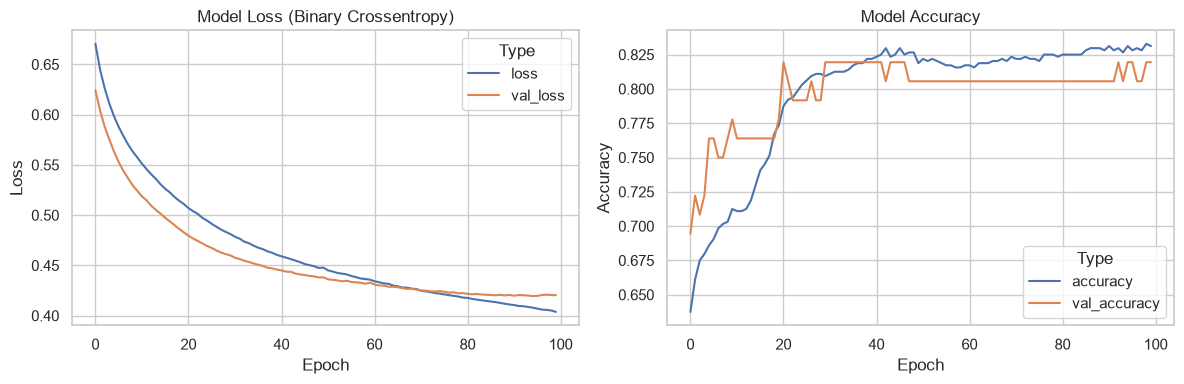

In [10]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import Dense
from tensorflow.keras.callbacks import EarlyStopping

titanic = sns.load_dataset('titanic')
features = ["pclass", "sex", "age", "sibsp", "parch", "fare", "embarked"]
X, y = titanic[features], titanic["survived"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

# 1. Valeurs Manquantes : on utilise les valeurs du train
fill = {"age": X_train["age"].median(), "embarked": X_train["embarked"].mode()[0]}
X_train = X_train.fillna(fill)
X_test = X_test.fillna(fill)

# 2. Variables categorielles [meme colonne pour train et test]
cat = ["sex", "embarked", "pclass"]
X_train =  pd.get_dummies(X_train, columns=cat, drop_first=True)
X_test = pd.get_dummies(X_test, columns=cat, drop_first=True);
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

# 3. Normalisation des Colonnes Numériaues (fit sur le terrain)
num = ["age", "fare"]
scaler = StandardScaler().fit(X_train[num])
X_train[num] = scaler.transform(X_train[num])
X_test[num] = scaler.transform(X_test[num])

# 4. Conversion en tableaux NumPy et verification des dimensions
X_train = X_train.values.astype("float32")
X_test = X_test.values.astype("float32")
print("Shape X_train : ",  X_train.shape, "| Shape X_test : ", X_test.shape)

model = Sequential([
    Input(shape=(X_train.shape[1], )),
    Dense(16, activation="relu"),
    Dense(1, activation="sigmoid"),
])
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

early = EarlyStopping(patience=10, restore_best_weights=True)
history = model.fit(X_train, y_train, epochs=100, batch_size=32,
                     validation_split=0.1, callbacks=[early], verbose=0)

pred = (model.predict(X_test) > 0.5).astype("int").ravel()
print(classification_report(y_test, pred))

# Convertir en DataFrame
history_df = pd.DataFrame(history.history)

# Préparer les données au format long
loss_df = history_df[['loss', 'val_loss']].reset_index().melt(
    id_vars='index', var_name='Type', value_name='Loss')
loss_df = loss_df.rename(columns={'index': 'Epoch'})

acc_df = history_df[['accuracy', 'val_accuracy']].reset_index().melt(
    id_vars='index', var_name='Type', value_name='Accuracy')
acc_df = acc_df.rename(columns={'index': 'Epoch'})

# Tracer avec seaborn
sns.set_theme(style="whitegrid")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

sns.lineplot(data=loss_df, x='Epoch', y='Loss', hue='Type', ax=ax1)
ax1.set_title('Model Loss (Binary Crossentropy)')

sns.lineplot(data=acc_df, x='Epoch', y='Accuracy', hue='Type', ax=ax2)
ax2.set_title('Model Accuracy')

plt.tight_layout()
plt.show()

## Comparaison 4, 16, 64 neurones cachées


--- Rapport pour 4 neurones cachés ---
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 
              precision    recall  f1-score   support

           0       0.80      0.93      0.86       110
           1       0.85      0.64      0.73        69

    accuracy                           0.82       179
   macro avg       0.82      0.78      0.79       179
weighted avg       0.82      0.82      0.81       179



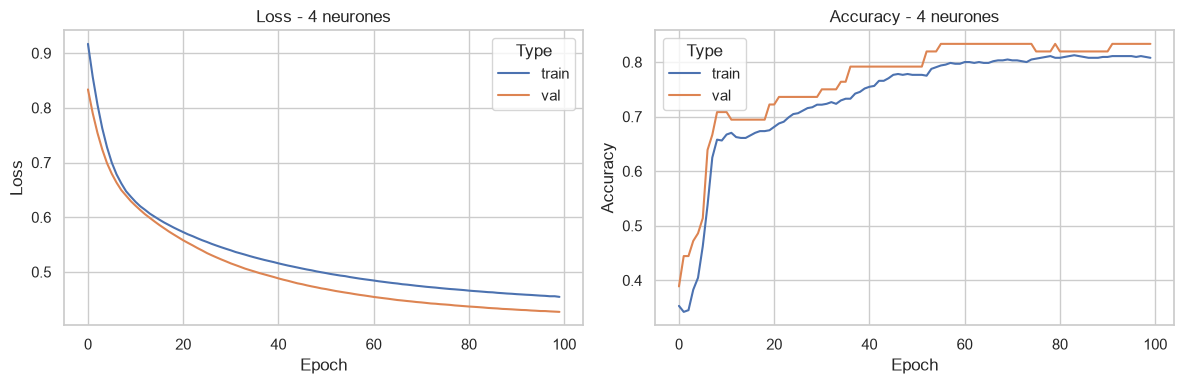


--- Rapport pour 16 neurones cachés ---
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 
              precision    recall  f1-score   support

           0       0.81      0.93      0.86       110
           1       0.85      0.65      0.74        69

    accuracy                           0.82       179
   macro avg       0.83      0.79      0.80       179
weighted avg       0.82      0.82      0.82       179



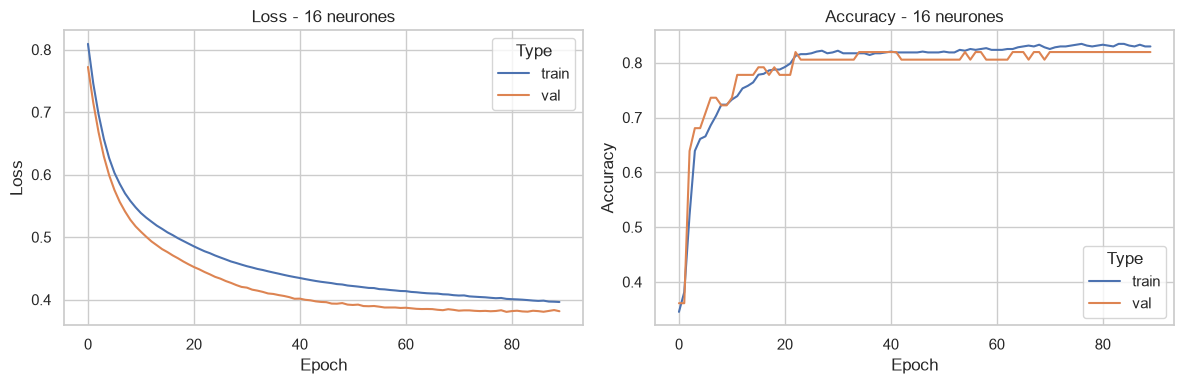


--- Rapport pour 64 neurones cachés ---
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 
              precision    recall  f1-score   support

           0       0.79      0.91      0.84       110
           1       0.81      0.61      0.69        69

    accuracy                           0.79       179
   macro avg       0.80      0.76      0.77       179
weighted avg       0.80      0.79      0.79       179



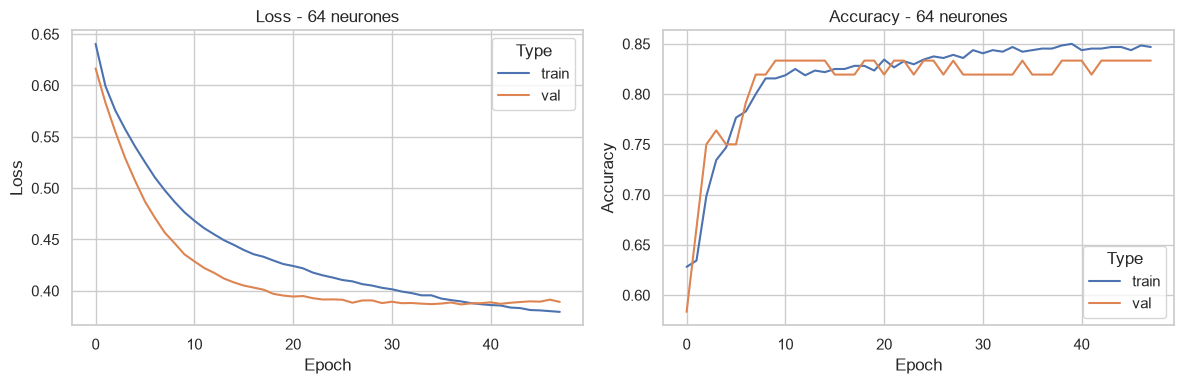

In [15]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import Dense
from tensorflow.keras.callbacks import EarlyStopping

# --- Préparation des données ---
titanic = sns.load_dataset('titanic')
features = ["pclass", "sex", "age", "sibsp", "parch", "fare", "embarked"]
X, y = titanic[features], titanic["survived"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

fill = {"age": X_train["age"].median(), "embarked": X_train["embarked"].mode()[0]}
X_train = X_train.fillna(fill)
X_test = X_test.fillna(fill)

cat = ["sex", "embarked", "pclass"]
X_train = pd.get_dummies(X_train, columns=cat, drop_first=True)
X_test = pd.get_dummies(X_test, columns=cat, drop_first=True)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

num = ["age", "fare"]
scaler = StandardScaler().fit(X_train[num])
X_train[num] = scaler.transform(X_train[num])
X_test[num] = scaler.transform(X_test[num])

X_train = X_train.values.astype("float32")
X_test = X_test.values.astype("float32")

# --- Boucle sur les tailles de couche cachée ---
hidden_units_list = [4, 16, 64]

for hidden_units in hidden_units_list:
    print(f"\n{'='*50}\n--- Rapport pour {hidden_units} neurones cachés ---\n{'='*50}")

    model = Sequential([
        Input(shape=(X_train.shape[1],)),
        Dense(hidden_units, activation="relu"),
        Dense(1, activation="sigmoid"),
    ])
    model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

    early = EarlyStopping(patience=10, restore_best_weights=True)
    history = model.fit(
        X_train, y_train,
        epochs=100,
        batch_size=32,
        validation_split=0.1,
        callbacks=[early],
        verbose=0
    )

    # Affichage du rapport complet
    pred = (model.predict(X_test) > 0.5).astype("int").ravel()
    report = classification_report(y_test, pred)
    print(report)

    # --- Préparation des données pour les 2 graphiques de cette config ---
    epochs = range(len(history.history["loss"]))

    loss_df = pd.DataFrame({
        "Epoch": list(epochs) * 2,
        "Type": ["train"] * len(epochs) + ["val"] * len(epochs),
        "Loss": history.history["loss"] + history.history["val_loss"]
    })

    acc_df = pd.DataFrame({
        "Epoch": list(epochs) * 2,
        "Type": ["train"] * len(epochs) + ["val"] * len(epochs),
        "Accuracy": history.history["accuracy"] + history.history["val_accuracy"]
    })

    # --- Affichage des 2 graphiques ---
    sns.set_theme(style="whitegrid")
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

    sns.lineplot(data=loss_df, x="Epoch", y="Loss", hue="Type", ax=ax1)
    ax1.set_title(f"Loss - {hidden_units} neurones")

    sns.lineplot(data=acc_df, x="Epoch", y="Accuracy", hue="Type", ax=ax2)
    ax2.set_title(f"Accuracy - {hidden_units} neurones")

    plt.tight_layout()
    plt.show()